In [ ]:
!pip install streamlit plotly openpyxl pyngrok


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 86.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 114.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.8 MB/s eta 0:00:00


In [ ]:
!ngrok config add-authtoken 2uqpbS2vnpexMcAaxRd5Ag5kC0a_DB6Vix8EciRZdihn3fKJ

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
from pyngrok import ngrok
ngrok.kill()  # coupe toutes les connexions actives


In [ ]:
from pyngrok import ngrok
import threading
import time

def run():
    !streamlit run app.py

thread = threading.Thread(target=run)
thread.start()
time.sleep(5)

url = ngrok.connect(8501)
print(f"🔗 Ton app Streamlit est ici : {url}")





  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.16.238.248:8502

🔗 Ton app Streamlit est ici : NgrokTunnel: "https://8769-34-16-238-248.ngrok-free.app" -> "http://localhost:8501"


In [ ]:
# app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.graph_objects as go

# Chargement des fichiers .xlsx
files = {
    "possession": "FB_team_season_stats_possession.xlsx",
    "shooting": "FB_team_season_stats_shooting.xlsx",
    "goal_creation": "FB_team_season_stats_goal_shot_creation.xlsx",
    "passing": "FB_team_season_stats_passing.xlsx",
    "defense": "FB_team_season_stats_defense.xlsx",
    "misc": "FB_team_season_stats_misc.xlsx"
}
dfs = {k: pd.read_excel(v) for k, v in files.items()}

# Paramètres
season = 2425

# Sélection dynamique des clubs disponibles
all_teams = dfs["passing"]
available_teams = all_teams[all_teams["season"] == season]["team"].dropna().unique()

# Sidebar Streamlit
st.sidebar.title("Configuration")

team1 = st.sidebar.selectbox("Sélectionner le club 1", sorted(available_teams), index=0)
team2 = st.sidebar.selectbox("Sélectionner le club 2", sorted(available_teams), index=1)
mode = st.sidebar.radio("Type de radar", ["Jeu avec ballon", "Jeu sans ballon"])

# Métriques
ball_metrics = {
    "Possession (%)": ("possession", "Poss"),
    "Passes progressives": ("passing", "PrgP"),
    "Réceptions progressives": ("possession", "PrgR"),
    "Courses progressives": ("possession", "PrgC"),
    "xA": ("passing", "xA"),
    "xAG": ("passing", "xAG"),
    "xG": ("shooting", "xG"),
    "SCA": ("goal_creation", "SCA"),
    "GCA": ("goal_creation", "GCA"),
    "Key Passes": ("passing", "KP"),
    "Centres vers la surface": ("passing", "CrsPA"),
    "Passes dans la surface": ("passing", "PPA"),
    "Passes dans le dernier quart": ("passing", "1/4"),
    "Passes tentées": ("passing", "Att"),
    "Passes complétées (%)": ("passing", "Cmp%"),
    "Centres": ("misc", "Crs"),
    "Distance totale des passes": ("passing", "TotDist")
}

offball_metrics = {
    "Tacles": ("defense", "Tkl"),
    "Tacles gagnés": ("defense", "TklW"),
    "Tacles défensifs": ("defense", "Def 3rd"),
    "Tacles milieu": ("defense", "Mid 3rd"),
    "Tacles offensifs": ("defense", "Att 3rd"),
    "Taux de réussite tacles (%)": ("defense", "Tkl%"),
    "Interceptions": ("defense", "Int"),
    "Tacles + Interceptions": ("defense", "Tkl+Int"),
    "Blocs": ("defense", "Blocks"),
    "Dégagements": ("defense", "Clr"),
    "Récupérations": ("misc", "Recov"),
    "Duels gagnés": ("misc", "Won"),
    "Duels perdus": ("misc", "Lost"),
    "Fautes": ("misc", "Fls"),
    "Fautes subies": ("misc", "Fld"),
    "Penalties concédés": ("misc", "PKcon"),
    "Penalties provoqués": ("misc", "PKwon"),
    "Cartons jaunes": ("misc", "CrdY")
}

metrics = ball_metrics if mode == "Jeu avec ballon" else offball_metrics

def prepare_data(metrics, team1, team2):
    stats = {team1: [], team2: []}
    hover_text = {team1: [], team2: []}
    labels = list(metrics.keys())

    for label, (df_key, column) in metrics.items():
        df = dfs[df_key]
        df = df[df["season"] == season]
        df[column] = pd.to_numeric(df[column], errors='coerce')
        max_val = df[column].max()

        for team in [team1, team2]:
            val = df[df["team"] == team][column].values
            raw = float(val[0]) if len(val) else 0.0
            norm = raw / max_val if max_val > 0 else 0.0
            stats[team].append(norm)
            hover_text[team].append(f"{label}: {raw:.2f}")

    # Fermer le cercle
    for team in [team1, team2]:
        stats[team] += stats[team][:1]
        hover_text[team] += hover_text[team][:1]
    labels += labels[:1]

    return stats, hover_text, labels

# Construction radar chart interactif
def plot_radar(stats, hover_texts, labels, team1, team2):
    fig = go.Figure()
    colors = {
        team1: "#1f77b4",
        team2: "#ff7f0e"
    }

    for team in [team1, team2]:
        fig.add_trace(go.Scatterpolar(
            r=stats[team],
            theta=labels,
            fill='toself',
            name=team,
            hovertext=hover_texts[team],
            hoverinfo='text',
            line=dict(color=colors[team], width=3)
        ))

    fig.update_layout(
        title=f"Radar Chart – {mode}",
        polar=dict(
            bgcolor="#1e1e1e",
            radialaxis=dict(visible=True, range=[0, 1], showticklabels=False, ticks=''),
            angularaxis=dict(tickfont=dict(size=10, color='white'))
        ),
        showlegend=True,
        paper_bgcolor="#1e1e1e",
        font=dict(color="white"),
        legend=dict(
            bgcolor="#2b2b2b",
            bordercolor="gray",
            borderwidth=1
        )
    )
    return fig

# Pipeline
stats, hovers, labels = prepare_data(metrics, team1, team2)
fig = plot_radar(stats, hovers, labels, team1, team2)
st.plotly_chart(fig, use_container_width=True)


2025-03-26 10:41:03.771 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-26 10:41:03.773 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-26 10:41:03.775 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-26 10:41:03.778 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-26 10:41:03.780 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-26 10:41:03.782 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-26 10:41:03.785 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-26 10:41:03.785 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

<ipython-input-8-800c8ea94909>:67: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final_clean["style_cluster"] = kmeans.fit_predict(X_scaled)
<ipython-input-8-800c8ea94909>:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final_clean["PCA1"] = pca_result[:, 0]
<ipython-input-8-800c8ea94909>:73: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.o

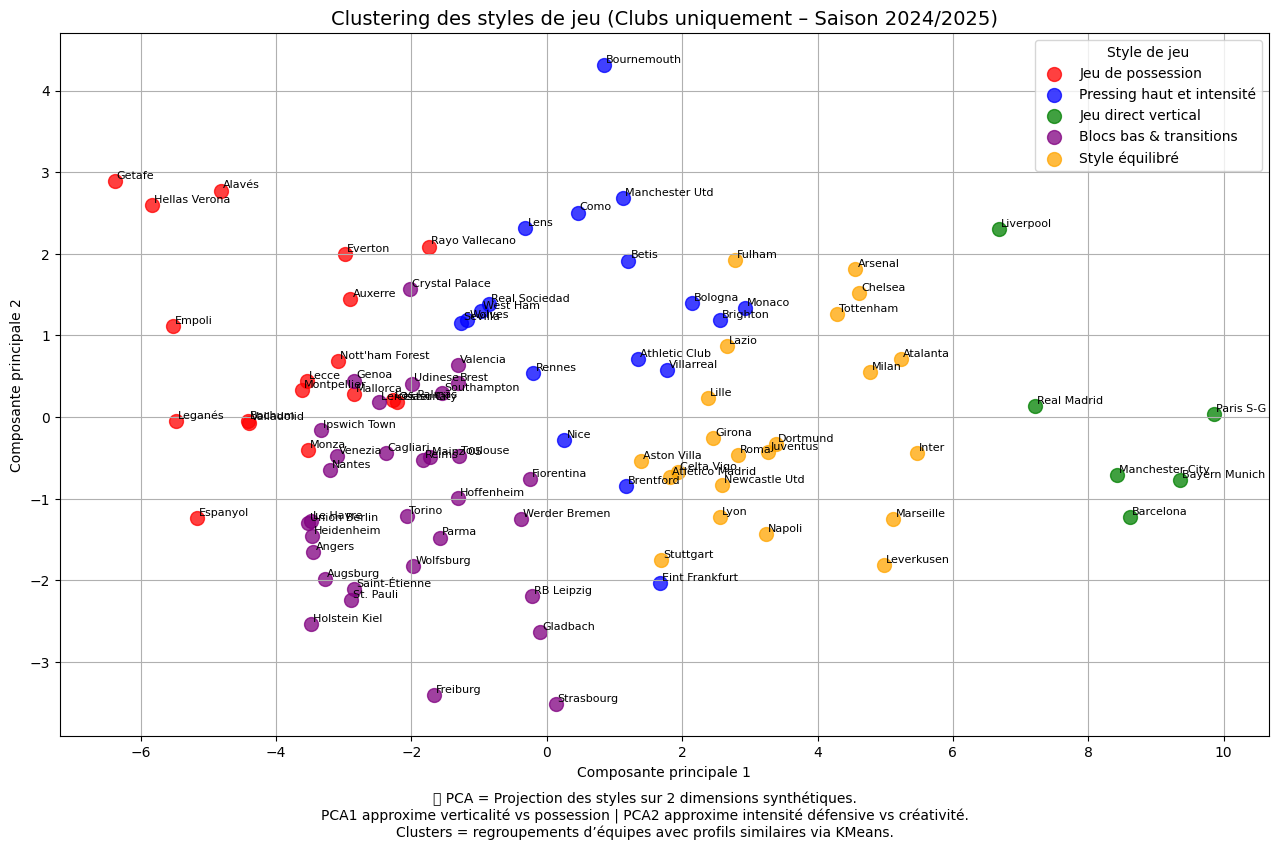

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Chargement des fichiers
files = {
    "possession": "FB_team_season_stats_possession.xlsx",
    "passing": "FB_team_season_stats_passing.xlsx",
    "passing_types": "FB_team_season_stats_passing_types.xlsx",
    "keeper_adv": "FB_team_season_stats_keeper_adv.xlsx",
    "defense": "FB_team_season_stats_defense.xlsx",
    "misc": "FB_team_season_stats_misc.xlsx",
    "shooting": "FB_team_season_stats_shooting.xlsx",
    "goal_creation": "FB_team_season_stats_goal_shot_creation.xlsx"
}
dfs = {k: pd.read_excel(v) for k, v in files.items()}

# Identifier les équipes nationales
unique_teams = dfs["possession"]["team"].dropna().unique()
national_teams = [team for team in unique_teams if " " not in team and team.isupper()]

# Filtrage : saison 2425, uniquement clubs
df_base = dfs["possession"][
    (dfs["possession"]["season"] == 2425) &
    (~dfs["possession"]["team"].isin(national_teams))
][["team", "season"]].drop_duplicates()

# Sélection des métriques pertinentes
style_features = [
    # Possession & construction
    ("possession", "Poss"), ("possession", "PrgC"), ("possession", "PrgR"),
    ("passing", "PrgP"), ("passing", "Cmp%"), ("possession", "Touches"),
    ("passing", "KP"), ("goal_creation", "SCA"), ("goal_creation", "GCA"),

    # Jeu direct et verticalité
    ("keeper_adv", "Launch%"), ("keeper_adv", "AvgLen"),
    ("passing", "Att.1"), ("passing_types", "Sw"),

    # Largeur et jeu sur les ailes
    ("misc", "Crs"), ("possession", "CPA"),

    # Défense & pressing
    ("defense", "Tkl"), ("defense", "Int"), ("defense", "Blocks"),
    ("defense", "Att 3rd"), ("keeper_adv", "#OPA/90"),

    # Discipline / agressivité
    ("misc", "Fls"), ("misc", "CrdY"), ("misc", "CrdR"),

    # Finition & dangerosité
    ("shooting", "xG"), ("shooting", "G/Sh")
]

# Fusion des features
df_final = df_base.copy()
for df_name, col in style_features:
    df_final = df_final.merge(dfs[df_name][["team", "season", col]], on=["team", "season"], how="left")

# Nettoyage
df_final_clean = df_final.dropna()
X = df_final_clean.drop(columns=["team", "season"])
X_scaled = StandardScaler().fit_transform(X)

# Clustering (KMeans)
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_final_clean["style_cluster"] = kmeans.fit_predict(X_scaled)

# PCA pour visualisation
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)
df_final_clean["PCA1"] = pca_result[:, 0]
df_final_clean["PCA2"] = pca_result[:, 1]

# Noms des styles (à titre indicatif)
cluster_names = {
    0: "Jeu de possession",
    1: "Pressing haut et intensité",
    2: "Jeu direct vertical",
    3: "Blocs bas & transitions",
    4: "Style équilibré"
}
df_final_clean["style_label"] = df_final_clean["style_cluster"].map(cluster_names)

# Visualisation avec matplotlib
colors = ['red', 'blue', 'green', 'purple', 'orange']
plt.figure(figsize=(13, 8))
for cluster in sorted(df_final_clean["style_cluster"].unique()):
    subset = df_final_clean[df_final_clean["style_cluster"] == cluster]
    plt.scatter(subset["PCA1"], subset["PCA2"], s=100, label=cluster_names[cluster], alpha=0.75, color=colors[cluster])

for _, row in df_final_clean.iterrows():
    plt.text(row["PCA1"] + 0.03, row["PCA2"] + 0.03, row["team"], fontsize=8)

plt.title("Clustering des styles de jeu (Clubs uniquement – Saison 2024/2025)", fontsize=14)
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.legend(title="Style de jeu", loc="best")
plt.grid(True)
plt.tight_layout()

# Légende du graphique (explication PCA)
plt.figtext(0.5, -0.05,
    "📌 PCA = Projection des styles sur 2 dimensions synthétiques.\n"
    "PCA1 approxime verticalité vs possession | PCA2 approxime intensité défensive vs créativité.\n"
    "Clusters = regroupements d’équipes avec profils similaires via KMeans.",
    wrap=True, horizontalalignment='center', fontsize=10)

plt.show()


<ipython-input-8-2b8aab3eaf09>:86: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="upper right", bbox_to_anchor=(1.2, 1))


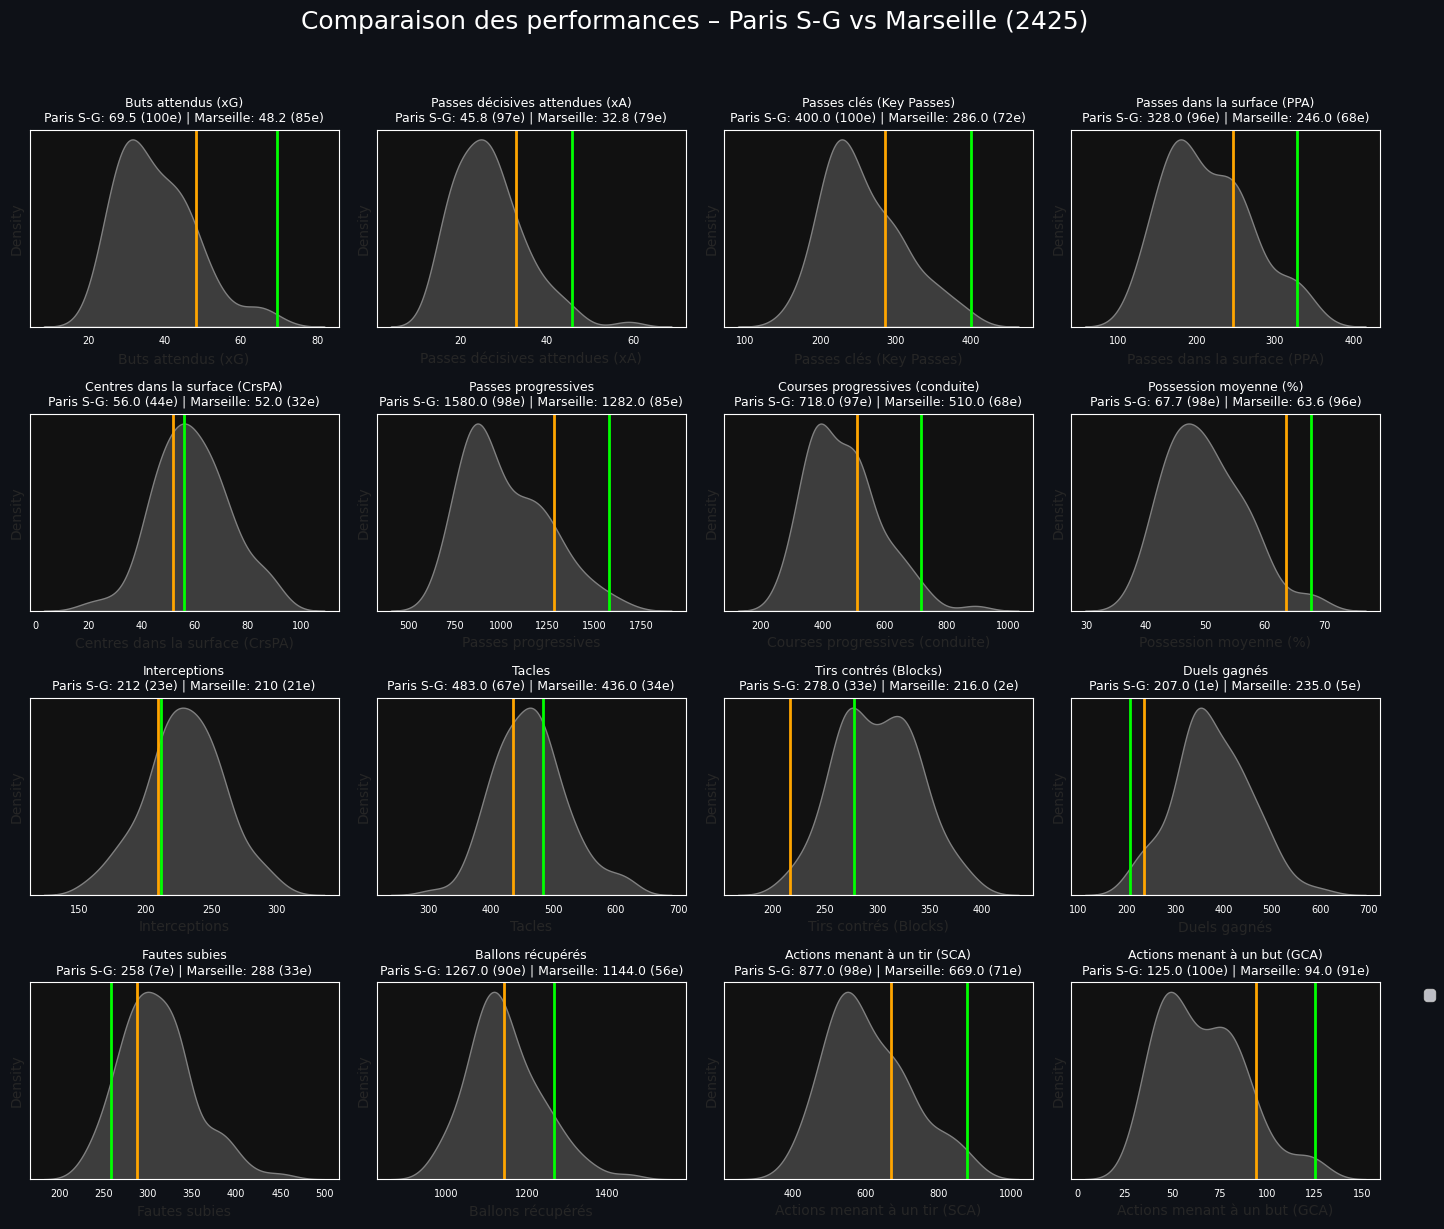

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import percentileofscore

# === PARAMÈTRES ===
club1 = "Paris S-G"
club2 = "Marseille"
saison = 2425

# === FICHIERS ===
files = {
    "possession": "FB_team_season_stats_possession.xlsx",
    "shooting": "FB_team_season_stats_shooting.xlsx",
    "goal_creation": "FB_team_season_stats_goal_shot_creation.xlsx",
    "passing": "FB_team_season_stats_passing.xlsx",
    "defense": "FB_team_season_stats_defense.xlsx",
    "misc": "FB_team_season_stats_misc.xlsx",
    "keeper_adv": "FB_team_season_stats_keeper_adv.xlsx",
    "passing_types": "FB_team_season_stats_passing_types.xlsx"
}
dfs = {k: pd.read_excel(v) for k, v in files.items()}

# === VARIABLES À ANALYSER ===
features = {
    "Buts attendus (xG)": ("shooting", "xG"),
    "Passes décisives attendues (xA)": ("passing", "xA"),
    "Passes clés (Key Passes)": ("passing", "KP"),
    "Passes dans la surface (PPA)": ("passing", "PPA"),
    "Centres dans la surface (CrsPA)": ("passing", "CrsPA"),
    "Passes progressives": ("passing", "PrgP"),
    "Courses progressives (conduite)": ("possession", "PrgC"),
    "Possession moyenne (%)": ("possession", "Poss"),
    "Interceptions": ("defense", "Int"),
    "Tacles": ("defense", "Tkl"),
    "Tirs contrés (Blocks)": ("defense", "Blocks"),
    "Duels gagnés": ("misc", "Won"),
    "Fautes subies": ("misc", "Fld"),
    "Ballons récupérés": ("misc", "Recov"),
    "Actions menant à un tir (SCA)": ("goal_creation", "SCA"),
    "Actions menant à un but (GCA)": ("goal_creation", "GCA"),
}

# === FUSION DES DONNÉES ===
df = dfs["passing"][["team", "season"]].drop_duplicates()
for label, (df_key, col) in features.items():
    sub = dfs[df_key][["team", "season", col]]
    sub = sub.rename(columns={col: label})
    sub[label] = pd.to_numeric(sub[label], errors="coerce")
    df = df.merge(sub, on=["team", "season"], how="left")

# === FILTRAGE SAISON ET CLUBS ===
df = df[df["season"] == saison].dropna()
club1_stats = df[df["team"] == club1].iloc[0]
club2_stats = df[df["team"] == club2].iloc[0]

# === AFFICHAGE GRAPHIQUE COMPARATIF ===
sns.set_style("dark")
plt.figure(figsize=(14, 12))
plt.suptitle(f"Comparaison des performances – {club1} vs {club2} ({saison})", fontsize=18, color="white", y=1.02)

for idx, label in enumerate(features.keys()):
    values = df[label].dropna().astype(float)
    val1 = club1_stats[label]
    val2 = club2_stats[label]
    pct1 = percentileofscore(values, val1)
    pct2 = percentileofscore(values, val2)

    plt.subplot(4, 4, idx + 1)
    if len(values.unique()) > 1:
        sns.kdeplot(values, fill=True, color="gray", alpha=0.4)

    plt.axvline(val1, color="lime", linewidth=2, label=club1 if idx == 0 else "")
    plt.axvline(val2, color="orange", linewidth=2, label=club2 if idx == 0 else "")

    title = f"{label}\n{club1}: {round(val1, 2)} ({int(pct1)}e) | {club2}: {round(val2, 2)} ({int(pct2)}e)"
    plt.title(title, fontsize=9, color="white")
    plt.xticks(color='white', fontsize=7)
    plt.yticks([], [])
    plt.gca().set_facecolor("#111111")
    plt.grid(False)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.gcf().patch.set_facecolor('#0e1117')
plt.legend(loc="upper right", bbox_to_anchor=(1.2, 1))
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Chargement des fichiers ---
schedule = pd.read_csv("FM_schedule.csv")
stats = pd.read_csv("FM_team_match_stats.csv")

# --- Nettoyage des colonnes ---
schedule["date"] = pd.to_datetime(schedule["date"], errors="coerce")
stats = stats.rename(columns={"game": "game_id"})
schedule["game_id"] = schedule["game_id"].astype(str)
stats["game_id"] = stats["game_id"].astype(str)

# --- Fusion des deux fichiers ---
merged = stats.merge(schedule, on="game_id")

# --- Filtrer saison 2425 (année 2025) ---
merged = merged[merged["date"].dt.year == 2025]

# --- Colonnes utiles ---
merged = merged[[
    "date", "team", "home_team", "away_team",
    "home_score", "away_score",
    "Expected goals (xG)", "Ball possession",
    "Total shots", "Accurate passes"
]]

# --- Équipes à comparer ---
teams = ["Paris S-G", "Marseille"]
data = merged[merged["team"].isin(teams)].sort_values("date", ascending=False)

# --- Derniers 5 matchs par équipe ---
last_matches = data.groupby("team").head(5).copy()

# --- Fonction de visualisation style FotMob ---
def plot_team_form(team_name, df, filename=None):
    df_team = df[df["team"] == team_name].sort_values("date")

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_title(team_name, fontsize=14, weight="bold")

    for i, (_, row) in enumerate(df_team.iterrows()):
        opponent = row["away_team"] if row["home_team"] == team_name else row["home_team"]
        is_home = row["home_team"] == team_name

        team_score = row["home_score"] if is_home else row["away_score"]
        opp_score = row["away_score"] if is_home else row["home_score"]

        # Résultat
        if team_score > opp_score:
            result = "✅ Win"
            color = "green"
        elif team_score < opp_score:
            result = "❌ Loss"
            color = "red"
        else:
            result = "➖ Draw"
            color = "orange"

        # Stats
        xg = row["Expected goals (xG)"]
        poss = row["Ball possession"]
        shots = row["Total shots"]
        passes = row["Accurate passes"]

        # Texte
        text = f"{result} {team_score}-{opp_score} vs {opponent}\n" \
               f"xG: {xg:.2f} | Poss: {poss}% | Shots: {shots} | Passes: {passes}"

        ax.text(0.5, 0.95 - i * 0.19, text, ha='center', fontsize=10,
                bbox=dict(boxstyle="round,pad=0.3", facecolor=color, alpha=0.2))

    ax.axis("off")
    fig.suptitle(f"Forme récente - {team_name}", fontsize=13, weight="bold")
    plt.tight_layout()

    if filename:
        fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.close(fig)

# --- Génération des visuels pour chaque club ---
plot_team_form("Paris S-G", last_matches, filename="forme_PSG.png")
plot_team_form("Marseille", last_matches, filename="forme_OM.png")


In [ ]:
import pandas as pd
import os
from functools import reduce
from xgboost import XGBRegressor
import numpy as np

# 1. Charger et fusionner les fichiers
data_dir = "/content/"  # Mets ici le bon chemin
files = [f for f in os.listdir(data_dir) if f.endswith(".xlsx")]
merge_keys = ['league', 'season', 'team']
dfs = []

for file in files:
    df = pd.read_excel(os.path.join(data_dir, file))
    suffix = os.path.splitext(file)[0].replace("FB_team_season_stats_", "")
    df = df.rename(columns={col: f"{col}_{suffix}" for col in df.columns if col not in merge_keys})
    dfs.append(df)

merged_df = reduce(lambda left, right: pd.merge(left, right, on=merge_keys, how='outer'), dfs)
merged_df = merged_df.loc[:, ~merged_df.columns.duplicated()]

# 2. Définir la cible
target = 'PPM_playing_time'

# 3. Sélection des features
exclude_keywords = ['Rank', 'Gls', 'GA', 'PK', 'Save%', 'CS', 'onxG', 'onGA', 'OG']
numerical_cols = merged_df.select_dtypes(include='number').columns.tolist()
features = [
    col for col in numerical_cols if col != target and not any(key in col for key in exclude_keywords)
]

# 4. Séparer entraînement et prédiction (saisons < 2425)
train_df = merged_df[merged_df['season'] < 2425].dropna(subset=features + [target])
predict_df = merged_df[merged_df['season'] == 2425].dropna(subset=features)

X_train = train_df[features]
y_train = train_df[target]
X_pred = predict_df[features]
teams_pred = predict_df[['team', 'league', 'season']].copy()

# 5. Entraîner le modèle
model = XGBRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 6. Prédiction pour la saison 2024-25
teams_pred["predicted_PPM"] = model.predict(X_pred)
teams_pred["predicted_rank"] = teams_pred.groupby("league")["predicted_PPM"].rank(ascending=False)

# 7. Affichage du classement simulé
print("\n🏅 Classement simulé 2024-25 (top 10) :")
print(teams_pred.sort_values(["league", "predicted_rank"]).head(10))

# 8. Analyse des variables les plus influentes
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n🧠 Top 20 variables influentes pour la performance (PPM) :")
print(importance_df.head(20))

# 9. Exporter le classement complet
teams_pred.sort_values(["league", "predicted_rank"]).to_excel("classement_simule_2024_25.xlsx", index=False)



🏅 Classement simulé 2024-25 (top 10) :
                team              league  season  predicted_PPM  \
111        Liverpool  ENG-Premier League    2425       2.276118   
100          Arsenal  ENG-Premier League    2425       2.059215   
115  Nott'ham Forest  ENG-Premier League    2425       1.743521   
105          Chelsea  ENG-Premier League    2425       1.652814   
112  Manchester City  ENG-Premier League    2425       1.615785   
114    Newcastle Utd  ENG-Premier League    2425       1.563540   
102      Bournemouth  ENG-Premier League    2425       1.546363   
104         Brighton  ENG-Premier League    2425       1.476745   
117        Tottenham  ENG-Premier League    2425       1.470594   
108           Fulham  ENG-Premier League    2425       1.466512   

     predicted_rank  
111             1.0  
100             2.0  
115             3.0  
105             4.0  
112             5.0  
114             6.0  
102             7.0  
104             8.0  
117             9.0  
10

In [ ]:
import pandas as pd
import os
from functools import reduce
from xgboost import XGBRegressor
import numpy as np

# 1. Charger et fusionner les fichiers
data_dir = "/content/"  # À adapter
files = [f for f in os.listdir(data_dir) if f.endswith(".xlsx")]
merge_keys = ['league', 'season', 'team']
dfs = []

for file in files:
    df = pd.read_excel(os.path.join(data_dir, file))
    suffix = os.path.splitext(file)[0].replace("FB_team_season_stats_", "")
    df = df.rename(columns={col: f"{col}_{suffix}" for col in df.columns if col not in merge_keys})
    dfs.append(df)

merged_df = reduce(lambda left, right: pd.merge(left, right, on=merge_keys, how='outer'), dfs)
merged_df = merged_df.loc[:, ~merged_df.columns.duplicated()]

# 2. Définir la cible
target = 'PPM_playing_time'

# 3. Sélection des features (en excluant certaines)
exclude_keywords = ['Rank', 'Gls', 'GA', 'PK', 'Save%', 'CS', 'onxG', 'onGA', 'OG']
numerical_cols = merged_df.select_dtypes(include='number').columns.tolist()
features = [
    col for col in numerical_cols if col != target and not any(key in col for key in exclude_keywords)
]

# 4. Nettoyage des colonnes avec trop de NaN (>50%)
threshold = 0.5
valid_cols = merged_df[features + [target]].isnull().mean() < threshold
clean_cols = valid_cols[valid_cols].index.tolist()

# Mettre à jour features avec uniquement les colonnes valides
features = [col for col in features if col in clean_cols]

# 5. Nettoyage global (lignes incomplètes)
merged_df_clean = merged_df.dropna(subset=features + [target])

# 6. Séparer entraînement (avant 2425) et prédiction (2425)
train_df = merged_df_clean[merged_df_clean['season'] < 2425]
predict_df = merged_df_clean[merged_df_clean['season'] == 2425]

# 7. X/y
X_train = train_df[features]
y_train = train_df[target]
X_pred = predict_df[features]
teams_pred = predict_df[['team', 'league', 'season']].copy()

# 8. Entraînement modèle
model = XGBRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 9. Prédiction
teams_pred["predicted_PPM"] = model.predict(X_pred)
teams_pred["predicted_rank"] = teams_pred.groupby("league")["predicted_PPM"].rank(ascending=False)

# 10. Résultats
print("\n🏅 Classement simulé 2024-25 (top 10) :")
print(teams_pred.sort_values(["league", "predicted_rank"]).head(10))

# 11. Importance des variables
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n🧠 Top 20 variables influentes pour la performance (PPM) :")
print(importance_df.head(20))


🏅 Classement simulé 2024-25 (top 10) :
                team              league  season  predicted_PPM  \
111        Liverpool  ENG-Premier League    2425       2.276118   
100          Arsenal  ENG-Premier League    2425       2.059215   
115  Nott'ham Forest  ENG-Premier League    2425       1.743521   
105          Chelsea  ENG-Premier League    2425       1.652814   
112  Manchester City  ENG-Premier League    2425       1.615785   
114    Newcastle Utd  ENG-Premier League    2425       1.563540   
102      Bournemouth  ENG-Premier League    2425       1.546363   
104         Brighton  ENG-Premier League    2425       1.476745   
117        Tottenham  ENG-Premier League    2425       1.470594   
108           Fulham  ENG-Premier League    2425       1.466512   

     predicted_rank  
111             1.0  
100             2.0  
115             3.0  
105             4.0  
112             5.0  
114             6.0  
102             7.0  
104             8.0  
117             9.0  
10

In [ ]:
train_df = merged_df_clean[merged_df_clean['season'] < 2425]
print("📚 Données d'entraînement utilisées :")
print(train_df.groupby("league")["season"].unique().apply(list))
print(f"\n🔢 Total lignes d'entraînement : {len(train_df)}")



📚 Données d'entraînement utilisées :
league
ENG-Premier League       [2021, 2122, 2223, 2324]
ESP-La Liga              [2021, 2122, 2223, 2324]
FRA-Ligue 1              [2021, 2122, 2223, 2324]
GER-Bundesliga           [2021, 2122, 2223, 2324]
INT-Women's World Cup                      [2324]
INT-World Cup                              [2223]
ITA-Serie A              [2021, 2122, 2223, 2324]
Name: season, dtype: object

🔢 Total lignes d'entraînement : 441


In [ ]:
files = {
    "possession": "FB_team_season_stats_possession.xlsx",
    "shooting": "FB_team_season_stats_shooting.xlsx",
    "goal_creation": "FB_team_season_stats_goal_shot_creation.xlsx",
    "passing": "FB_team_season_stats_passing.xlsx",
    "defense": "FB_team_season_stats_defense.xlsx",
    "misc": "FB_team_season_stats_misc.xlsx",
    "keeper_adv": "FB_team_season_stats_keeper_adv.xlsx",
    "passing_types": "FB_team_season_stats_passing_types.xlsx",
    "player_season": "US_player_season_stats.csv",
    "matchsheet": "ESPN_matchsheet.csv"
}


In [ ]:
import pandas as pd


In [ ]:
for k, v in files.items():
    try:
        print(f"Lecture de : {v}")
        if v.endswith(".xlsx"):
            df = pd.read_excel(v)
        else:
            df = pd.read_csv(v)
        print(f"{v} chargé avec succès.")
    except Exception as e:
        print(f"Erreur de lecture du fichier : {v}")
        print(e)


Lecture de : FB_team_season_stats_possession.xlsx
FB_team_season_stats_possession.xlsx chargé avec succès.
Lecture de : FB_team_season_stats_shooting.xlsx
FB_team_season_stats_shooting.xlsx chargé avec succès.
Lecture de : FB_team_season_stats_goal_shot_creation.xlsx
FB_team_season_stats_goal_shot_creation.xlsx chargé avec succès.
Lecture de : FB_team_season_stats_passing.xlsx
FB_team_season_stats_passing.xlsx chargé avec succès.
Lecture de : FB_team_season_stats_defense.xlsx
FB_team_season_stats_defense.xlsx chargé avec succès.
Lecture de : FB_team_season_stats_misc.xlsx
FB_team_season_stats_misc.xlsx chargé avec succès.
Lecture de : FB_team_season_stats_keeper_adv.xlsx
FB_team_season_stats_keeper_adv.xlsx chargé avec succès.
Lecture de : FB_team_season_stats_passing_types.xlsx
FB_team_season_stats_passing_types.xlsx chargé avec succès.
Lecture de : US_player_season_stats.csv
US_player_season_stats.csv chargé avec succès.
Lecture de : ESPN_matchsheet.csv
ESPN_matchsheet.csv chargé ave